# Argentina: Capítulo IV well data and Vaca Muerta

Argentina's Secretaría de Energía publishes monthly production per well
("Capítulo IV"). The connector resolves the per-year CSV through the portal's
CKAN API — no hardcoded file URL. `ingest` downloads it, upserts it into the
local Parquet store, and we analyze from there.

In [1]:

import matplotlib.pyplot as plt

import ogprod

# Categorical palette in fixed slot order (colorblind-safe adjacency)
PALETTE = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "lines.linewidth": 2,
    "figure.figsize": (9, 4),
    "font.size": 11,
})

# The store lives in ~/.local/share/ogprod/store unless $OGPROD_STORE says otherwise.
db = ogprod.Store()
db

Store('/Users/mralbu/.local/share/ogprod/store')

## Ingest

One call: fetch, parse, upsert — plus the wells listing on the first run.
Re-running is idempotent and picks up restatements; `just ingest argentina
--year 2026` is the shell equivalent.

In [2]:
print(db.ingest("argentina", year=2026))

argentina: 1,985,769 production rows 2026-01..2026-09 in 1 partition(s); entities: 84,242


In [3]:
frame = db.production(source="argentina")
print(f"{len(frame):,} rows, {frame['entity_id'].nunique():,} wells, "
      f"{frame['period'].min():%Y-%m}..{frame['period'].max():%Y-%m}")
frame.head()

1,985,769 rows, 83,418 wells, 2026-01..2026-09


,source,entity_type,entity_id,entity_name,field,basin,region,operator,period,product,volume
0,argentina,well,10000,"SJ.Nq.ET""E"".x-1",EL TRAPIAL,NEUQUINA,Neuquén,CHEVRON ARGENTINA S.R.L.,2026-01-01,gas,0.0
1,argentina,well,10000,"SJ.Nq.ET""E"".x-1",EL TRAPIAL,NEUQUINA,Neuquén,CHEVRON ARGENTINA S.R.L.,2026-01-01,oil,0.0
2,argentina,well,10000,"SJ.Nq.ET""E"".x-1",EL TRAPIAL,NEUQUINA,Neuquén,CHEVRON ARGENTINA S.R.L.,2026-01-01,water,0.0
3,argentina,well,10000,"SJ.Nq.ET""E"".x-1",EL TRAPIAL,NEUQUINA,Neuquén,CHEVRON ARGENTINA S.R.L.,2026-02-01,gas,0.0
4,argentina,well,10000,"SJ.Nq.ET""E"".x-1",EL TRAPIAL,NEUQUINA,Neuquén,CHEVRON ARGENTINA S.R.L.,2026-02-01,oil,0.0


## One basin is the story

Vaca Muerta (in the Neuquina basin) turned Argentina into a shale producer;
the canonical `basin` column makes that visible without any source-specific
code. The product filter is pushed down into the store scan.

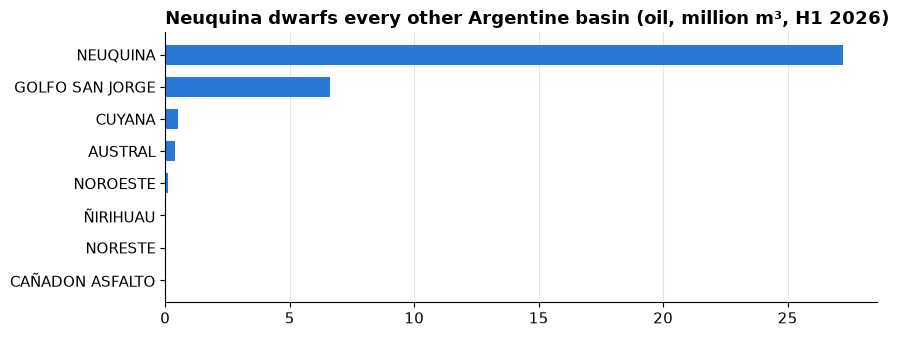

In [4]:
oil = db.production(source="argentina", product="oil")
by_basin = oil.groupby("basin")["volume"].sum().sort_values()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(by_basin.index, by_basin.values / 1e6, color=PALETTE[0], height=0.62)
ax.set_title("Neuquina dwarfs every other Argentine basin (oil, million m³, H1 2026)")
ax.grid(axis="y", visible=False)
fig.tight_layout()

## Monthly country totals

Again two panels — oil and gas live on different scales, so they never share
an axis.

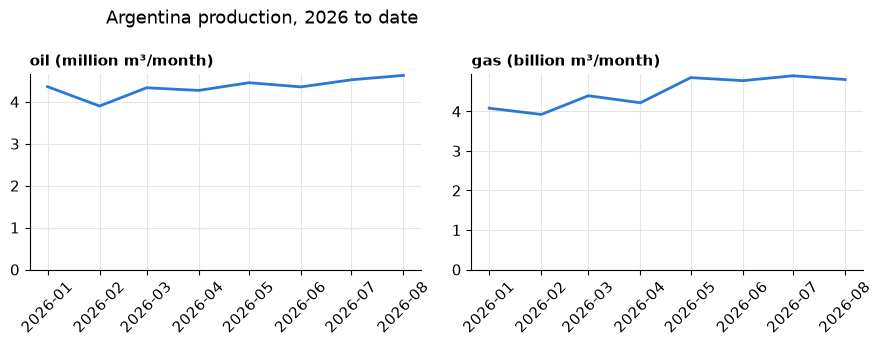

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, product, unit, scale in (
    (axes[0], "oil", "million m³/month", 1e6),
    (axes[1], "gas", "billion m³/month", 1e9),
):
    series = frame[frame["product"] == product]
    # the newest month is still being reported by operators — drop it
    monthly = (series.groupby("period")["volume"].sum() / scale).iloc[:-1]
    ax.plot(monthly.index, monthly.values)
    ax.set_title(f"{product} ({unit})", fontsize=11)
    ax.set_ylim(bottom=0)
    ax.set_xticks(monthly.index, [f"{p:%Y-%m}" for p in monthly.index], rotation=45)
fig.suptitle("Argentina production, 2026 to date", x=0.125, ha="left")
fig.tight_layout()

## Operators

`operator`, `field`, `region` all come normalized, so ranking is one groupby.

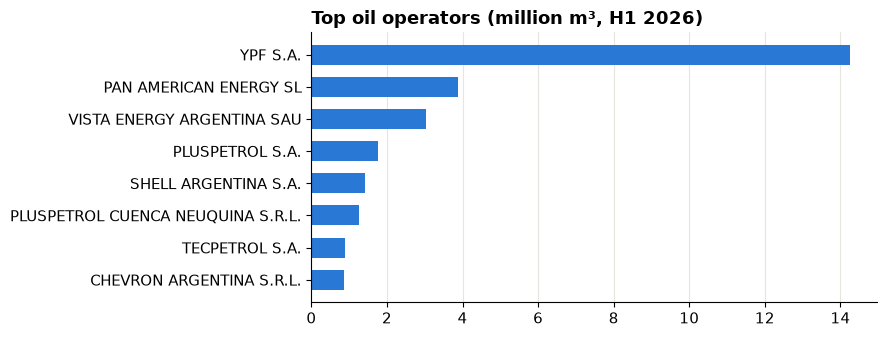

In [6]:
top = oil.groupby("operator")["volume"].sum().nlargest(8).sort_values()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(top.index, top.values / 1e6, color=PALETTE[0], height=0.62)
ax.set_title("Top oil operators (million m³, H1 2026)")
ax.grid(axis="y", visible=False)
fig.tight_layout()

Cross-source note: `ogprod.schema.canonical_id` namespaces the source-native
well IDs (`"argentina:130589"`, `"anp:7-TPI-1-RJS"`) when you mix frames from
several regulators in one table. And because everything above lives in one
store, `db.sql` queries across sources directly, while `db.coverage()` shows
what the store holds:

In [7]:
wells = db.sql(
    "SELECT source, count(DISTINCT entity_id) AS entities FROM production GROUP BY source"
)
print(wells.to_string(index=False))
db.coverage()

   source  entities
argentina     83418
    sodir       136
      anp      6655


,source,rows,producing_entities,first_period,last_period,stored_entities
0,anp,28124,6655,2023-06-01,2023-06-01,31310
1,argentina,1985769,83418,2026-01-01,2026-09-01,84242
2,sodir,142275,136,1971-06-01,2026-07-01,142
